<a href="https://colab.research.google.com/github/braulio-orellano/ConnectaTel-analysis/blob/main/S7_Version_Estudiante_Project_ConnectaTel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel.

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


---
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [ ]:
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [ ]:
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [ ]:
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [ ]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [ ]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [ ]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [ ]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [ ]:
# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [ ]:
# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos.

 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
- Indica qué harías: ¿imputar, eliminar, ignorar?

**Diagnóstico**

- En el dataset users, la columna city tiene 469 nulos que representa el 11.73% (0.11725) y la columna churn_date tiene 3534 nulos que representan el 88.35% (0.88350).
- En el dataset uasge, la columna duración tiene 22076 nulos que representan 55.19% (0.55190), lenght tiene 17896 con representación del 44.74% (0.44740) y date tiene 50 nulos con 0.13% (0.00125).
- users['city'] Investigar para imputar ya que representa 11.73% nulos.
- users['churn_date'] Ignorar al estar entre 80-90% de nulos (88.35%).
- usage['date'] Imputar al ser menor al 5% (0.13% nulos).
- usage['duration'] Ignorar tiene 55.19% de nulos.
- usage['length'] Ignorar al tener 44.74% de nulos.


### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [ ]:
# explorar columnas numéricas de users
print(users[['user_id', 'age']].describe())

            user_id          age
count   4000.000000  4000.000000
mean   11999.500000    33.739750
std     1154.844867   123.232257
min    10000.000000  -999.000000
25%    10999.750000    32.000000
50%    11999.500000    47.000000
75%    12999.250000    63.000000
max    13999.000000    79.000000


- La columna `user_id` cuenta con 4,000 registros completos en el rango de 10000 a 13999 (media 11999.5, mediana 11999.5, desviación estándar 1154.84), compatible con una secuencia continua de identificadores sin huecos evidentes.
- La columna `age` presenta 4,000 registros con mediana de 47.0 años y rango intercuartílico de 32.0 a 63.0 años, pero contiene el valor centinela -999.0 como mínimo, lo que distorsiona la media (33.74) e infla la desviación estándar (123.23).

In [ ]:
# explorar columnas numéricas de usage
print(usage.describe())

                id       user_id      duration        length
count  40000.00000  40000.000000  17924.000000  22104.000000
mean   20000.50000  12002.405975      5.202237     52.127398
std    11547.14972   1157.279564      6.842701     56.611183
min        1.00000  10000.000000      0.000000      0.000000
25%    10000.75000  10996.000000      1.437500     37.000000
50%    20000.50000  12013.000000      3.500000     50.000000
75%    30000.25000  13005.000000      6.990000     64.000000
max    40000.00000  13999.000000    120.000000   1490.000000


- Las columnas `id` y `user_id` ambas tienen 40,000 registros completos; id va de 1 a 40000 (media 20000.5, mediana 20000.5) como identificador correlativo de eventos, y user_id oscila entre 10000 y 13999 (media ~12002.41, mediana 12013.0), alineado con el universo de usuarios.
- Las columnas duration y lenght ambas muestran asimetría positiva marcada (media superior a la mediana), valores mínimos de 0.0 y máximos extremos (120.0 en duration y 1490.0 en length), además de alta ausencia de datos (duration con 17,924 no nulos y length con 22,104 no nulos sobre 40,000 filas).

In [ ]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
print(users[columnas_user].describe())

          city    plan
count     3531    4000
unique       7       2
top     Bogotá  Basico
freq       808    2595


- La columna `city` registra 3531 valores no nulos (469 faltantes sobre 4000 filas) distribuidos en 7 categorías únicas, liderada por Bogotá con 808 ocurrencias. (Nota: revisa sus valores únicos para confirmar que el centinela '?' no cuente como una de las 7 categorías).
- La columna `plan` está completa en los 4000 registros y se divide en 2 categorías únicas, con predominio de Basico (2595 registros, 64.9%).

In [ ]:
# explorar columna categórica de usage
usage['type'].value_counts()

text    22092
call    17908
Name: type, dtype: int64

- La columna `type` cuenta con 40000 eventos divididos en dos tipos de actividad: text con 22092 registros (55.2%) y call con 17908 registros (44.8%), sin valores faltantes. (Nota: figura con dtype: int64 en el output, probable efecto de visualización/codificación del entorno, aunque sus etiquetas visibles son text y call).


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso.

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?

**Diagnóstico**
- En las columnas age, city y reg_date del dataset users se observan valores invalidos o sentinels.
- En age reemplazaría -999 por la mediana válida, en city sustituir '?' por pd.NA y en reg_date parsear con pd.to_datetime(..., errors='coerce'), enmascarar fechas fuera de rango y mantener el tipo fecha (datetime64 / pd.NaT).

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [ ]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [ ]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [ ]:
# Revisar los años presentes en `reg_date` de users
print(users['reg_date'].dt.year.unique())

[2022 2026 2023 2024]


En `reg_date`, tras convertir a fecha con pd.to_datetime(..., errors='coerce'), aparecen los años [2022, 2026, 2023, 2024], donde 2026 queda fuera del rango esperado dado que los datos registrados llegan hasta el año 2024.

In [ ]:
# Revisar los años presentes en `date` de usage
print(usage['date'].dt.year.unique())

[2024.   nan]


En `date`, tras convertir a fecha con pd.to_datetime(..., errors='coerce'), solo aparece el año 2024 junto con nan (que corresponde a los 50 registros nulos detectados previamente en usage['date']), sin años fuera de rango ni fechas futuras.  
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

**Diagnóstico**
- Sí, en users['reg_date'] aparece el año 2026 (fuera del límite de registro hasta 2024), mientras que en usage['date'] solo figura 2024 y nan.
- arcar como nulas (pd.NaT) las fechas de users['reg_date'] posteriores al rango válido (hasta 2024) conservando el tipo datetime64, y mantener usage['date'] sin cambios en su rango actual.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [ ]:
# Reemplazar -999 por la mediana de age
age_mediana = users['age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [ ]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
users['city'].describe()

count       3435
unique         6
top       Bogotá
freq         808
Name: city, dtype: object

In [ ]:
# Marcar fechas futuras como NA para reg_date
hoy = pd.Timestamp.now()
fuera_de_rango = users['reg_date'] > hoy
users['reg_date'] = users['reg_date'].mask(fuera_de_rango, pd.NA)

# Verificar cambios
users['reg_date'].describe()

count                    4000
unique                   3961
top       2026-05-10 00:00:00
freq                       40
first     2022-01-01 00:00:00
last      2026-05-10 00:00:00
Name: reg_date, dtype: object

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [ ]:
# Verificación MAR en usage (Missing At Random) para duration
usage['dur_na'] = usage['duration'].isna()

print(pd.crosstab(usage['type'], usage['dur_na'], margins=True))
print("\nProporción de nulos en duration por type:")
print(usage.groupby('type')['dur_na'].mean())

dur_na  False   True    All
type                       
call    17908      0  17908
text       16  22076  22092
All     17924  22076  40000

Proporción de nulos en duration por type:
type
call    0.000000
text    0.999276
Name: dur_na, dtype: float64


In [ ]:
# Verificación MAR en usage (Missing At Random) para length
usage['len_na'] = usage['length'].isna()

print(pd.crosstab(usage['type'], usage['len_na'], margins=True))
print("\nProporción de nulos en length por type:")
print(usage.groupby('type')['len_na'].mean())

len_na  False   True    All
type                       
call       12  17896  17908
text    22092      0  22092
All     22104  17896  40000

Proporción de nulos en length por type:
type
call    0.99933
text    0.00000
Name: len_na, dtype: float64


Se confirma un patrón MAR (estructural/condicional) dependiente de la columna `type`, se mantienen como nulos (NaN) sin imputar ni eliminar registros. La ausencia responde a la lógica del negocio (los mensajes text no tienen duración de llamada y las llamadas call no tienen longitud de caracteres).

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico.

**Instrucciones:**:
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [ ]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby('user_id', as_index=False).agg(cant_mensajes=('is_text', 'sum'),
                                                         cant_llamadas=('is_call', 'sum'),
                                                         cant_minutos_llamada=('duration', 'sum'))

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={'is_text': 'cant_mensajes',
                                      'is_call': 'cant_llamadas',
                                      'duration': 'cant_minutos_llamada'})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how='left')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [ ]:
# Resumen estadístico de las columnas numéricas
cols_num = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

cols_existentes = [c for c in cols_num if c in user_profile.columns]

resumen_num = user_profile[cols_existentes].describe(percentiles=[0.25, 0.5, 0.75]).T
resumen_num['mediana'] = user_profile[cols_existentes].median()
resumen_num['iqr'] = resumen_num['75%'] - resumen_num['25%']

print(resumen_num)

                       count       mean        std   min    25%    50%  \
age                   4000.0  48.122250  17.690408  18.0  33.00  47.00   
cant_mensajes         3999.0   5.524381   2.358416   0.0   4.00   5.00   
cant_llamadas         3999.0   4.478120   2.144238   0.0   3.00   4.00   
cant_minutos_llamada  3999.0  23.317054  18.168095   0.0  11.12  19.78   

                         75%     max  mediana     iqr  
age                   63.000   79.00    47.00  30.000  
cant_mensajes          7.000   17.00     5.00   3.000  
cant_llamadas          6.000   15.00     4.00   3.000  
cant_minutos_llamada  31.415  155.69    19.78  20.295  


In [ ]:
# Distribución porcentual del tipo de plan
dist_plan = pd.DataFrame({'cantidad_usuarios': user_profile['plan'].value_counts(dropna=False),
                          'porcentaje': (user_profile['plan'].value_counts(dropna=False, normalize=True) * 100).round(2)})

print(dist_plan)

         cantidad_usuarios  porcentaje
Basico                2595       64.88
Premium               1405       35.12


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada`

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda)

**Hint**  
Para cada histograma,
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

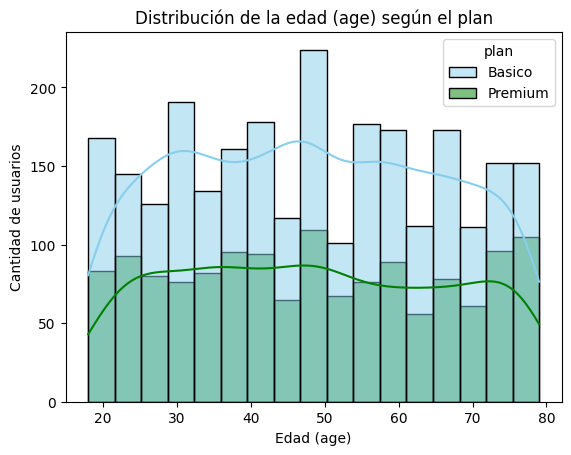

In [ ]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile,
            x='age',
            hue='plan',
            palette=['skyblue', 'green'],
            kde=True)

plt.title('Distribución de la edad (age) según el plan')
plt.xlabel('Edad (age)')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights:
- Distribución: La edad barca aproximadamente entre los 18 y los 80 años con una distribución bastante uniforme y aproximadamente simétrica (sin sesgo pronunciado hacia la derecha o izquierda), destacando un pico alrededor de los 47–50 años.
- Comparación por plan: El plan Basico concentra de forma consistente mayor cantidad de usuarios que el plan Premium a lo largo de casi todos los rangos de edad, sin que exista una diferencia etaria marcada que separe a un plan del otro.

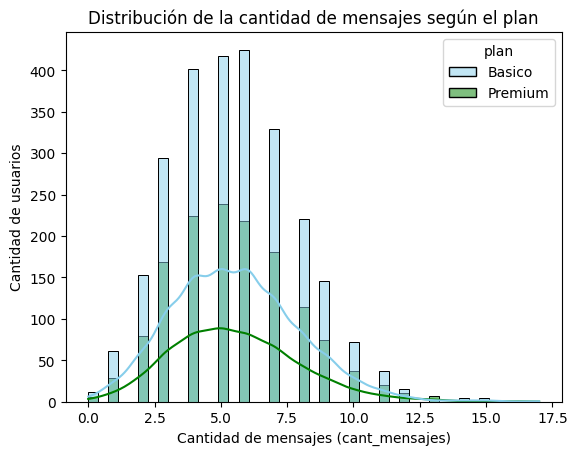

In [ ]:
# Histograma para visualizar la cant_mensajes
sns.histplot(
    data=user_profile,
    x='cant_mensajes',
    hue='plan',
    palette=['skyblue', 'green'],
    kde=True)

plt.title('Distribución de la cantidad de mensajes según el plan')
plt.xlabel('Cantidad de mensajes (cant_mensajes)')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights:
- Distribución: La cantidad de mensajes (cant_mensajes) se concentra principalmente entre 3 y 8 mensajes (con pico alrededor de 5–6) y presenta un leve sesgo a la derecha con una cola hacia valores más altos (cerca de 15–17 mensajes).
- Comparación por plan: Ambos planes siguen un patrón de forma similar, aunque el plan Basico acumula mayor cantidad de usuarios en casi todos los niveles de mensajes debido a su mayor base general de usuarios.

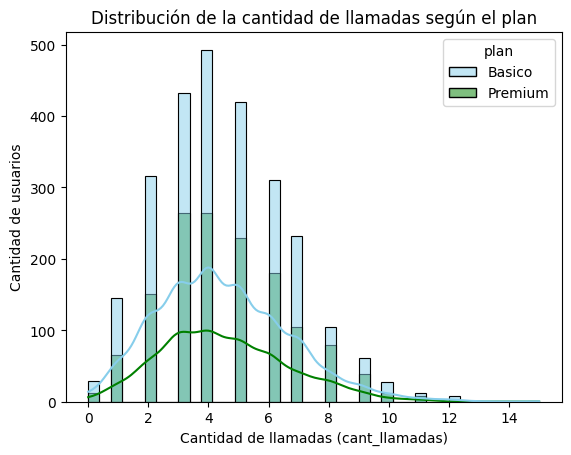

In [ ]:
# Histograma para visualizar la cant_llamadas
sns.histplot(
    data=user_profile,
    x='cant_llamadas',
    hue='plan',
    palette=['skyblue', 'green'],
    kde=True)

plt.title('Distribución de la cantidad de llamadas según el plan')
plt.xlabel('Cantidad de llamadas (cant_llamadas)')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights:
- Distribución: a cantidad de llamadas (cant_llamadas) presenta un ligero sesgo a la derecha, concentrando la mayoría de los usuarios entre 2 y 7 llamadas (con el pico principal en 4 llamadas) y extendiendo una cola hacia valores más altos cercanos a 12–15 llamadas.
- Comparación por plan: Ambos planes siguen un comportamiento muy similar alrededor de los mismos valores centrales, aunque el plan Basico mantiene una mayor cantidad de usuarios en cada barra respecto al plan Premium.

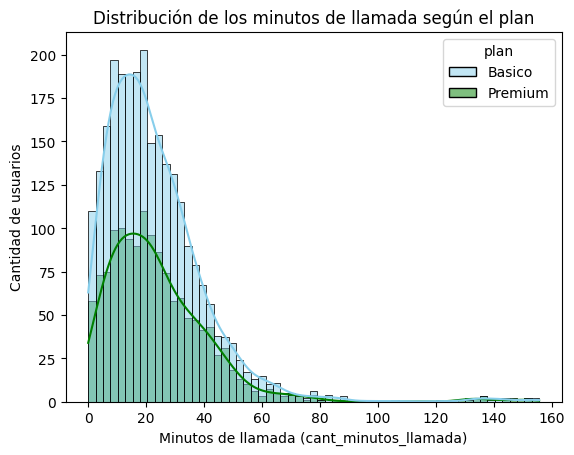

In [ ]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(
    data=user_profile,
    x='cant_minutos_llamada',
    hue='plan',
    palette=['skyblue', 'green'],
    kde=True)

plt.title('Distribución de los minutos de llamada según el plan')
plt.xlabel('Minutos de llamada (cant_minutos_llamada)')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights:
- Distribución: Los minutos de llamada presentan una distribución marcadamente sesgada a la derecha (asimetría positiva), concentrando la mayor parte de los usuarios entre los 5 y 35 minutos (con el pico principal alrededor de los 15–20 minutos) y extendiendo una cola larga hacia valores extremos cercanos a los 140–155 minutos.
- omparación por plan: Ambos planes siguen una forma de consumo casi idéntica con su pico en el mismo rango de minutos, aunque el plan Basico mantiene un mayor volumen de usuarios en prácticamente todos los intervalos frente al plan Premium.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age`
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

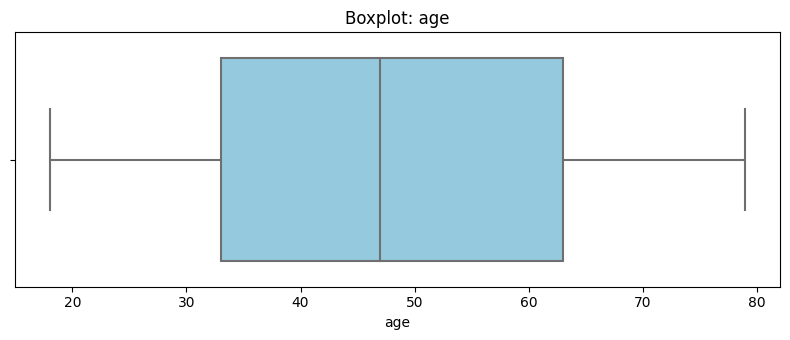

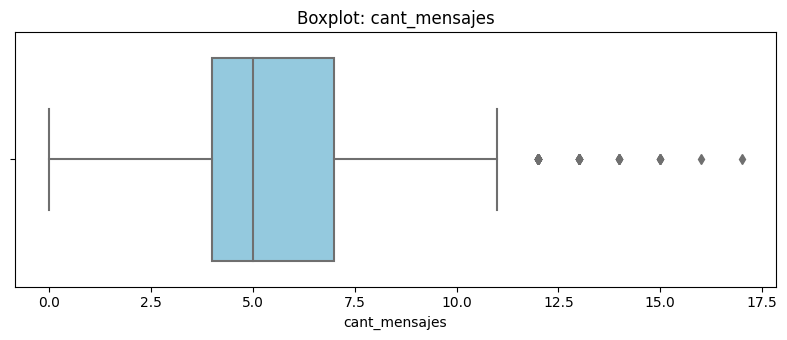

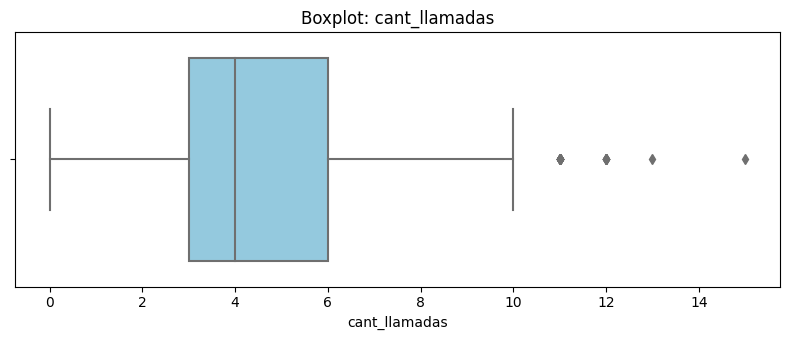

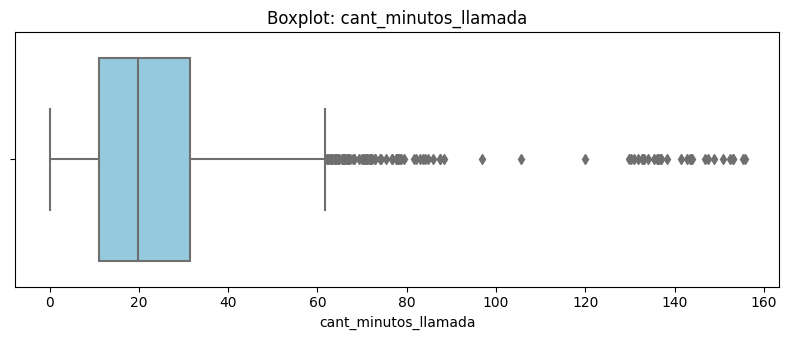

In [ ]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(8, 3.5))
    sns.boxplot(data=user_profile, x=col, color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

💡Insights:
- Age: No presenta outliers; la distribución abarca aproximadamente de 18 a 80 años con mediana cercana a 47 y rango intercuartílico entre 33 y 63, reflejando una base de clientes amplia y bien distribuida.
- cant_mensajes: Presenta outliers superiores (valores por encima de 11–12 mensajes, llegando hasta 17), frente a una mediana de 5 y IQR aproximado de 4 a 7.
- cant_llamadas: Presenta outliers superiores (valores por encima de 10 llamadas, hasta 15), con mediana en 4 y concentración central entre 3 y 6 llamadas.
- cant_minutos_llamada: Presenta múltiples outliers superiores a partir de 62 minutos (extendiendo una cola marcada hasta 155 minutos), con mediana alrededor de 20 minutos y concentración central entre 10 y 32 minutos.

In [ ]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada']

for col in columnas_limites:
  q1 = user_profile[col].quantile(0.25)
  q3 = user_profile[col].quantile(0.75)
  iqr = q3 - q1
  limite_superior = q3 + 1.5 * iqr
  outliers = user_profile[user_profile[col] > limite_superior]

  print(f'--- {col} ---')
  print(f'Q1 (25%): {q1:.2f} | Q3 (75%): {q3:.2f} | IQR: {iqr:.2f}')
  print(f'Límite superior: {limite_superior:.2f}')
  print(
      f'Cantidad de outliers superiores: {len(outliers)} '
      f'({len(outliers) / len(user_profile) * 100:.2f}%)\n'
  )

--- cant_mensajes ---
Q1 (25%): 4.00 | Q3 (75%): 7.00 | IQR: 3.00
Límite superior: 11.50
Cantidad de outliers superiores: 46 (1.15%)

--- cant_llamadas ---
Q1 (25%): 3.00 | Q3 (75%): 6.00 | IQR: 3.00
Límite superior: 10.50
Cantidad de outliers superiores: 30 (0.75%)

--- cant_minutos_llamada ---
Q1 (25%): 11.12 | Q3 (75%): 31.41 | IQR: 20.30
Límite superior: 61.86
Cantidad de outliers superiores: 109 (2.73%)



In [ ]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights:
- cant_mensajes: Mantener. Con Q1 = 4, Q3 = 7 ($\text{IQR} = 3$, límite superior IQR $= 11.5$) y un máximo de 17, los valores extremos son plausibles y representan usuarios con mayor actividad de mensajería; eliminarlos recortaría comportamiento real sin evidencia de error de registro.
- cant_llamadas: Mantener. Con Q1 = 3, Q3 = 6 ($\text{IQR} = 3$, límite superior IQR $= 10.5$) y un máximo de 15, los valores superiores reflejan usuarios frecuentes dentro de un rango operativo realista, por lo que conviene conservarlos para preservar la representatividad del uso
- cant_minutos_llamada: Mantener. Con Q1 = 11.12, Q3 = 31.42 ($\text{IQR} = 20.30$, límite superior IQR $\approx 61.87$) y un máximo de 155.69 frente a una mediana de 19.78 y media de 23.32, la cola superior evidencia heavy users legítimos; descartarlos subestimaría el volumen total de minutos y el comportamiento de los clientes de alto consumo.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [ ]:
# Crear columna grupo_uso
condiciones = [
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),
    (user_profile['cant_llamadas'] < 10)
    & (user_profile['cant_mensajes'] < 10)]

categorias = ['Bajo uso', 'Uso medio']

user_profile['grupo_uso'] = np.select(condiciones, categorias, default='Alto uso')

In [ ]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [ ]:
# Crear columna grupo_edad
condiciones_edad = [
    user_profile['age'] < 30,
    user_profile['age'] < 60]

categorias_edad = ['Joven', 'Adulto']

user_profile['grupo_edad'] = np.select(
    condiciones_edad, categorias_edad, default='Adulto Mayor')

In [ ]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

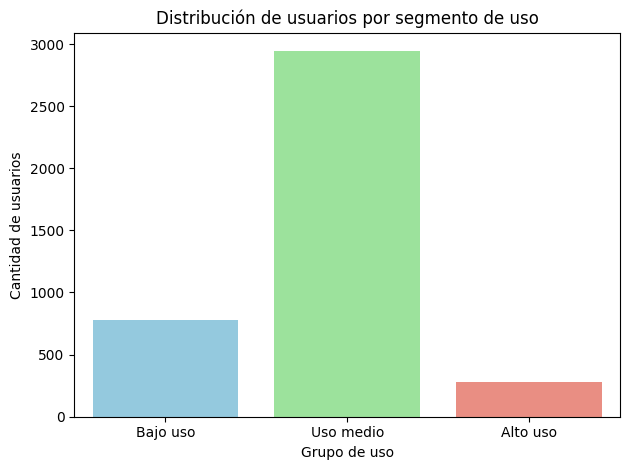

In [ ]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile,
    x='grupo_uso',
    order=['Bajo uso', 'Uso medio', 'Alto uso'],
    palette=['skyblue', 'lightgreen', 'salmon'])

plt.title('Distribución de usuarios por segmento de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')
plt.tight_layout()
plt.show()

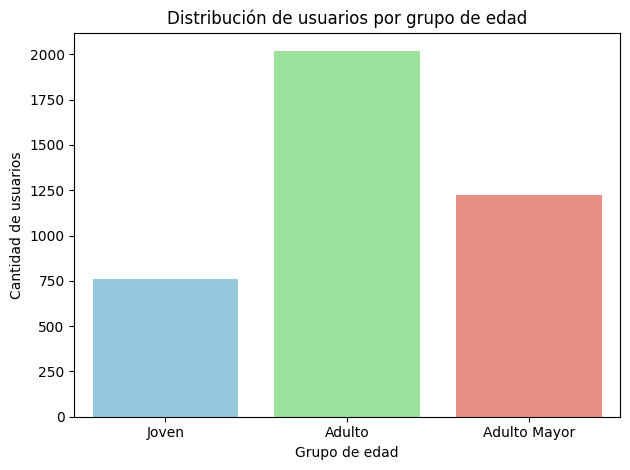

In [ ]:
# Visualización de los segmentos por edad
sns.countplot(
    data=user_profile,
    x='grupo_edad',
    order=['Joven', 'Adulto', 'Adulto Mayor'],
    palette=['skyblue', 'lightgreen', 'salmon'])

plt.title('Distribución de usuarios por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')
plt.tight_layout()
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:**
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- Valores faltantes en uso (NaN) y cruce: En el dataset de uso existían registros faltantes (NaN) en las métricas de actividad ([completar con cantidad exacta de filas / % por columna]); se conservaron inicialmente para respetar la lógica de negocio y, tras el left join hacia user_profile (3,999 usuarios), se imputaron con 0 para representar ausencia de actividad registrada sin perder clientes.
- Asimetría y valores atípicos superiores: Las variables de uso (cant_mensajes, cant_llamadas y cant_minutos_llamada) presentan sesgo a la derecha y outliers por encima del límite superior IQR (11.5 en mensajes con máximo 17; 10.5 en llamadas con máximo 15; y 61.87 en minutos con máximo 155.69). Se mantuvieron en el análisis porque corresponden a clientes con alto consumo real (heavy users) y no a errores de captura.


🔍 **Segmentos por Edad**
- Cobertura transversal sin sesgo etario: La base (18 a 80 años, mediana cercana a 47 y rango intercuartílico entre 33 y 63) se distribuye de forma amplia y equilibrada entre Joven (< 30), Adulto (30–59) y Adulto Mayor (>= 60), sin una frontera etaria que divida drásticamente la elección de plan.
- Predominio volumétrico del plan Básico: El plan Basico concentra consistentemente mayor cantidad de usuarios que el plan Premium en prácticamente todos los tramos de edad, evidenciando una base masiva de entrada sobre la cual construir estrategias de upselling.


📊 **Segmentos por Nivel de Uso**
- Núcleo de actividad concentrado: La mayoría de los clientes se ubica en niveles moderados de interacción —con medianas de 5 mensajes, 4 llamadas y 19.78 minutos de llamada— mientras que una minoría concentra picos altos de consumo (Alto uso).
- Comportamiento homogéneo entre planes: Tanto Basico como Premium muestran curvas de forma similar en mensajes, llamadas y minutos, lo que indica que tener plan Premium no implica necesariamente un patrón de llamadas o mensajes radicalmente distinto al de Basico en las métricas observadas.


➡️ Esto sugiere que ConnectaTel tiene una base amplia y estable en el plan Basico junto con un grupo de usuarios de alto consumo (outliers superiores y segmento de Alto uso) que representan una oportunidad clara de monetización y retención, mientras que los usuarios de Bajo uso requieren acciones de activación para evitar fuga (churn).


💡 **Recomendaciones**
- Estrategia de upselling hacia Premium: Diseñar ofertas de migración desde Basico hacia Premium enfocadas en usuarios con uso medio-alto o picos recurrentes en minutos/mensajes, destacando beneficios diferenciales claros que justifiquen el salto de plan.
- Planes modulares y retención por segmento: Crear paquetes escalonados (por ejemplo, bolsas enfocadas en minutos/voz para heavy users de llamadas y propuestas de valor simples o beneficios de bienvenida para Bajo uso y distintos grupos etarios) para maximizar el valor del cliente sin castigar el consumo legítimo de los usuarios más activos.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`